# Revision analyses (v5.1, frozen model)

Analyses requested in the pre-submission review. The model, priors, statistics and trained networks are those of
the frozen v5.1 run: the pipeline is executed once with its caches, then each analysis below runs on the cached
networks. Nothing is retrained; only analyses R5 (misspecification) and R6 (PPC under a less sparse prior)
run new simulations.

| § | Review point | Analysis |
|---|---|---|
| R1 | Major 1 (pseudoreplication) | patient-level OFF/ON tests, linear mixed models, cluster-bootstrap CIs, FDR; hierarchical posterior of every candidate change (patients → hemispheres) |
| R2 | Major 2, 4.2, 4.3 | HFO notch/HPI sensitivity: spectra before/after notching, usable bins, wider exclusions, notch-free bands, HPI-line amplitude OFF vs ON, EMG- and transient-masked HFO, resampling response |
| R3 | Major 6, 4.7 | model-free test of the β–HFO dissociation; PAC partial correlations and mixed model |
| R4 | 4.5 | sensitivity of the Δw_GS posterior to the sparsity of the change prior (importance reweighting) |
| R5 | Major 3 | misspecified fixed parameters (w_SG, w_GG, τ_S/τ_G, BG delays): is Δw_GS still recovered, without false decreases? |
| R6 | 4.6 | posterior predictive β change under a less sparse prior; predictive interval widths |
| R7 | Major 4 | Oxford restricted to bipolar channels |
| R8 | 4.1 | channel-selection sensitivity (β-best instead of HFO-best STN pair) |
| R9 | Major 8, 4.4 | clinical associations; simulation partitions |

All tables are written to `OUT_DIR/revision/`, figures to `OUT_DIR/revision/figures/`. Runtime ≈ 3–4 h
(pipeline with caches ≈ 1.5–2 h, R5 ≈ 45 min, R2/R8 data reloading ≈ 15 min, R6 ≈ 10 min).

## 0. Settings

In [1]:
from pathlib import Path

PIPELINE = Path(r"pd_pac_v51_circuit.py")   # ← the v5.1 pipeline script you ran
DS_ROOT = r"<local path>"               # ← as in the v5.1 run
OUT_DIR = r"pd_pac_v4_outputs"              # ← SAME output folder as the v5.1 run (caches)
GPU_ID = 1
QUICK = False                               # must match the v5.1 run
RUN_OXFORD_REV = True                       # R7 needs the Oxford section of the pipeline
MISSPEC_N = 48                              # R5: simulated pairs per case (decrease / no decrease) per condition
SEED_REV = 20261120
RUN_ONLY = None                             # e.g. {"R2", "R5b"} to run only these analyses; None = all
NULL_REPS = 6                               # R5b: null cohorts simulated per hemisphere (pure nuisance)

## 1. Run the frozen pipeline (caches reused)

In [ ]:
import re

src = PIPELINE.read_text(encoding="utf-8")
OVERRIDES = {"DS_ROOT": f"Path(r\"{DS_ROOT}\")", "OUT_DIR": f"Path(r\"{OUT_DIR}\")", "QUICK": str(QUICK),
             "RUN_COUPLING": "False", "RUN_OXFORD": str(RUN_OXFORD_REV), "RUN_JOINT": "True", "GPU_ID": str(GPU_ID)}
for name, value in OVERRIDES.items():
    line = f"{name} = {value}"
    src, n = re.subn(rf"^{name}\s*=.*$", lambda _m, line=line: line, src, count=1, flags=re.M)
    assert n == 1, f"could not find the setting {name} in {PIPELINE}"
exec(compile(src, str(PIPELINE), "exec"), globals())

In [3]:
import traceback
from fractions import Fraction
from statsmodels.stats.multitest import multipletests

REV = OUT_DIR / "revision"; REVF = REV / "figures"; REVF.mkdir(parents=True, exist_ok=True)
SUMMARY = {}                                   # key numbers collected for the response letter


def run(fn):
    """Run one analysis; a failure is reported and the notebook continues."""
    if RUN_ONLY is not None and fn.__name__.split("_")[0] not in RUN_ONLY:
        print(f"[{fn.__name__}: skipped]"); return
    t0 = time.time()
    try:
        fn()
    except Exception:
        print(f"!! {fn.__name__} failed:"); traceback.print_exc()
    print(f"[{fn.__name__}: {(time.time() - t0) / 60:.1f} min]")


def paired_frame(df, metric):
    o = df[df.med == "MedOff"].set_index(["subject", "side"])[metric]; n = df[df.med == "MedOn"].set_index(["subject", "side"])[metric]
    ii = o.index.intersection(n.index)
    d = pd.DataFrame(dict(off=o[ii].astype(float).values, on=n[ii].astype(float).values),
                     index=pd.MultiIndex.from_tuples(list(ii), names=["subject", "side"])).dropna()
    d["delta"] = d.on - d.off
    return d.reset_index()


def hedges(a, b):
    d = a - b; n = len(d)
    return d.mean() / d.std(ddof=1) * (1 - 3 / (4 * (n - 1) - 1)) if n > 2 and d.std() > 0 else np.nan


def cluster_boot_ci(d, stat=np.mean, n=4000, seed=0):
    """95% CI of a statistic of hemisphere deltas, resampling patients (clusters)."""
    rng = np.random.default_rng(seed); subs = d.subject.unique(); g = {s: d.delta[d.subject == s].values for s in subs}
    bs = [stat(np.concatenate([g[s] for s in rng.choice(subs, len(subs))])) for _ in range(n)]
    return np.percentile(bs, [2.5, 97.5])


def mixed_delta(d):
    """Δ ~ 1 + (1 | patient): population mean change with patient random intercepts."""
    import statsmodels.formula.api as smf
    for method in ("lbfgs", "powell", "nm"):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                m = smf.mixedlm("delta ~ 1", d, groups=d["subject"]).fit(reml=True, method=method, disp=False)
            ci = m.conf_int().loc["Intercept"].values
            if np.all(np.isfinite(ci)):
                return m.params["Intercept"], ci[0], ci[1], m.pvalues["Intercept"], float(m.cov_re.iloc[0, 0])
        except Exception:
            pass
    return (np.nan,) * 5

## R1. Pseudoreplication: patient-level statistics and hierarchical posteriors

OFF vs ON at hemisphere and patient level (Δ = ON − OFF; CI: cluster bootstrap over patients;
LMM: Δ ~ 1 + (1|patient); q: Benjamini–Hochberg within primary and within secondary metrics)
        metric  primary  n_hemi  n_pat  mean_off  mean_on  p_hemi  g_hemi  p_patient  g_patient  delta_mean  delta_ci95_lo  delta_ci95_hi  lmm_delta  lmm_ci_lo  lmm_ci_hi  p_lmm  patient_var  q_hemi  q_patient  q_lmm
  stn_beta_res     True      37     19    0.2046   0.1297  0.0001  0.6582     0.0008     0.7239     -0.0749        -0.1233        -0.0345    -0.0751    -0.1202    -0.0299 0.0011       0.0075  0.0001     0.0024 0.0034
stn_hfo_excess     True      37     19    0.0492   0.0657  0.0286 -0.3090     0.1042    -0.3945      0.0164        -0.0024         0.0356     0.0169    -0.0025     0.0363 0.0872       0.0009  0.0286     0.1042 0.0872
 stn_hfo_ratio     True      37     19   -0.0176   0.0479  0.0000 -0.5853     0.0028    -0.4247      0.0656         0.0235         0.1001     0.0583     0.0096   

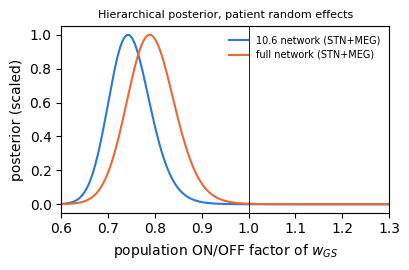

[R1_hierarchical: 0.9 min]


In [4]:
DESC = ["stn_beta_res", "stn_hfo_excess", "stn_hfo_ratio", "stn_hfo_peak_f", "stn_pac_z", "stn_burst_dur", "stn_ap_exp",
        "meg_beta_res", "meg_pac_z", "coh_beta", "delay_ms", "tremor_idx"]
PRIMARY = ["stn_beta_res", "stn_hfo_excess", "stn_hfo_ratio"]


def R1_descriptive():
    rows = []
    for m in DESC:
        if m not in M_DS:
            continue
        d = paired_frame(M_DS, m)
        P = d.groupby("subject")[["off", "on"]].mean(); P["delta"] = P.on - P.off       # patient = mean of hemispheres
        est, lo, hi, p_mix, var_u = mixed_delta(d)
        ci_h = cluster_boot_ci(d)
        rows.append(dict(metric=m, primary=m in PRIMARY, n_hemi=len(d), n_pat=len(P),
                         mean_off=d.off.mean(), mean_on=d.on.mean(),
                         p_hemi=stats.wilcoxon(d.off, d.on).pvalue, g_hemi=hedges(d.off.values, d.on.values),
                         p_patient=stats.wilcoxon(P.off, P.on).pvalue if len(P) > 5 else np.nan,
                         g_patient=hedges(P.off.values, P.on.values),
                         delta_mean=d.delta.mean(), delta_ci95_lo=ci_h[0], delta_ci95_hi=ci_h[1],
                         lmm_delta=est, lmm_ci_lo=lo, lmm_ci_hi=hi, p_lmm=p_mix, patient_var=var_u))
    T = pd.DataFrame(rows)
    for col in ("p_hemi", "p_patient", "p_lmm"):
        T[col.replace("p_", "q_")] = np.nan
        sec = ~T.primary
        T.loc[T.primary, col.replace("p_", "q_")] = multipletests(T.loc[T.primary, col].fillna(1), method="fdr_bh")[1]
        T.loc[sec, col.replace("p_", "q_")] = multipletests(T.loc[sec, col].fillna(1), method="fdr_bh")[1]
    print("OFF vs ON at hemisphere and patient level (Δ = ON − OFF; CI: cluster bootstrap over patients;\n"
          "LMM: Δ ~ 1 + (1|patient); q: Benjamini–Hochberg within primary and within secondary metrics)")
    print(T.round(4).to_string(index=False)); T.to_csv(REV / "R1_offon_patient_level.csv", index=False)
    SUMMARY["R1_desc"] = T.set_index("metric")[["p_hemi", "p_patient", "p_lmm", "q_lmm", "lmm_delta", "lmm_ci_lo", "lmm_ci_hi"]]


def p0_density(D, w, q=J_PCHANGE):
    """Change-prior density (per component): q·U(−w, w) + (1 − q)·N(0, (0.02 w)²)."""
    slab = (np.abs(D) <= 1.001 * w) / (2 * w)        # joint_samples keeps |Δ| ≤ 1.001 w
    spike = np.exp(-0.5 * (D / (J_SPIKE * w)) ** 2) / (np.sqrt(2 * np.pi) * J_SPIKE * w)
    return q * slab + (1 - q) * spike


def flat_likelihood(samples_d, w):
    """Posterior samples under the change prior → Gaussian approximation of the likelihood (flat-prior posterior)."""
    wt = 1.0 / np.maximum(p0_density(samples_d, w), 1e-300); wt /= wt.sum()
    m = np.sum(wt * samples_d); v = np.sum(wt * (samples_d - m) ** 2)
    return m, v, 1.0 / np.sum(wt ** 2)


def hierarchical_normal(m, v, subj, w, n_mu=401, n_s=40):
    """m_ij ~ N(μ + u_i, σ² + v_ij), u_i ~ N(0, τ²); flat μ on [−w, w], half-normal(w/2) on τ, σ; grid posterior."""
    mu_g = np.linspace(-w, w, n_mu); s_g = np.linspace(1e-3, w, n_s)
    subs = pd.unique(subj); logp = np.full((n_mu, n_s, n_s), 0.0)
    prior_s = -0.5 * (s_g / (w / 2)) ** 2
    for si, sg in enumerate(s_g):            # σ
        for ti, tg in enumerate(s_g):        # τ
            ll = np.zeros(n_mu)
            for s in subs:
                k = subj == s; mi, vi = m[k], v[k]
                C = tg ** 2 * np.ones((k.sum(), k.sum())) + np.diag(sg ** 2 + vi)
                Ci = np.linalg.inv(C); _, ld = np.linalg.slogdet(C)
                r = mi[None, :] - mu_g[:, None]
                ll += -0.5 * (np.einsum("ai,ij,aj->a", r, Ci, r) + ld)
            logp[:, ti, si] = ll + prior_s[si] + prior_s[ti]
    P = np.exp(logp - logp.max()); P /= P.sum()
    pm = P.sum((1, 2)); cdf = np.cumsum(pm)
    q = lambda a: mu_g[np.searchsorted(cdf, a)]
    pt = P.sum((0, 2)); ps = P.sum((0, 1))
    return dict(mu_med=q(.5), mu_lo=q(.05), mu_hi=q(.95), P_mu_neg=pm[mu_g < 0].sum(),
                tau_med=s_g[np.searchsorted(np.cumsum(pt), .5)], sigma_med=s_g[np.searchsorted(np.cumsum(ps), .5)]), (mu_g, pm)


def R1_hierarchical():
    out, curves = [], {}
    for label, SS, cols in (("10.6 network (STN+MEG)", JS_DS, lambda s: s[:, len(JP):]),
                            ("full network (STN+MEG)", FS_DS, lambda s: s[:, nP:nP + nM])):
        keys = list(SS); subj = np.array([k[0] for k in keys])
        for k, p in enumerate(JP):
            w = J_W[k]; mv = np.array([flat_likelihood(cols(SS[key])[:, k], w) for key in keys])
            h, curve = hierarchical_normal(mv[:, 0], mv[:, 1], subj, w)
            # patient-weighted cohort mean under the original prior: average hemispheres within patient, then patients
            rng = np.random.default_rng(0)
            draws = {key: cols(SS[key])[rng.integers(0, len(SS[key]), 4000), k] for key in keys}
            pat = np.stack([np.mean([draws[key] for key in keys if key[0] == s], 0) for s in pd.unique(subj)]).mean(0)
            fmt = (lambda x: np.exp(x)) if JOINT[p][0] == "log" else (lambda x: x)
            out.append(dict(network=label, param=p, scale="ON/OFF factor" if JOINT[p][0] == "log" else "additive",
                            hier_median=fmt(h["mu_med"]), hier_lo90=fmt(h["mu_lo"]), hier_hi90=fmt(h["mu_hi"]), P_hier_decrease=h["P_mu_neg"],
                            tau_between_patients=h["tau_med"], sigma_within=h["sigma_med"],
                            patient_mean_median=fmt(np.median(pat)), patient_mean_lo90=fmt(np.percentile(pat, 5)),
                            patient_mean_hi90=fmt(np.percentile(pat, 95)), P_patient_mean_decrease=(pat < 0).mean(),
                            min_ESS_flat=mv[:, 2].min(), n_hemi=len(keys), n_patients=len(pd.unique(subj))))
            if p == "w_GS":
                curves[label] = curve
    T = pd.DataFrame(out)
    print("Cohort OFF→ON change: hierarchical model (patients → hemispheres, flat-prior likelihoods) and patient-weighted\n"
          "cohort mean (original change prior); compare with Table 4 of the manuscript")
    print(T.round(3).to_string(index=False)); T.to_csv(REV / "R1_hierarchical_changes.csv", index=False)
    SUMMARY["R1_hier_wGS"] = T[T.param == "w_GS"]
    fig, ax = plt.subplots(figsize=(4.2, 2.8))
    for (lab, (mu_g, pm)), c in zip(curves.items(), ("#2a78d6", "#eb6834")):
        ax.plot(np.exp(mu_g), pm / pm.max(), color=c, label=lab)
    ax.axvline(1, color="k", lw=.6); ax.set_xlabel(r"population ON/OFF factor of $w_{GS}$"); ax.set_ylabel("posterior (scaled)")
    ax.set_xlim(.6, 1.3); ax.legend(frameon=False, fontsize=7); ax.set_title("Hierarchical posterior, patient random effects", fontsize=8)
    fig.tight_layout(); fig.savefig(REVF / "R1_hierarchical_wGS.png", dpi=300); plt.show()


run(R1_descriptive)
run(R1_hierarchical)

## R2. HFO and the notch filters (head-position coils, line harmonics), EMG, transients, resampling

Every ds004998 recording is reloaded once, exactly as in the pipeline (same file, same 122-s rest segment), and kept
in two versions: notched and resampled as in the pipeline, and **un-notched** (for spectra and HPI-line
amplitudes). HFO statistics are recomputed with 1-s Welch windows, so windows containing EMG bursts or HFO-band
transients can be dropped.

  0cGdk9 MedOff: done
  0cGdk9 MedOn: done
  2IU8mi MedOff: done
  2IU8mi MedOn: done
  2IhVOz MedOff: done
  2IhVOz MedOn: done
  6m9kB5 MedOff: done
  6m9kB5 MedOn: done
  8RgPiG MedOff: done
  8RgPiG MedOn: done
  AB2PeX MedOff: done
  AB2PeX MedOn: done
  AbzsOg MedOff: done
  AbzsOg MedOn: done
  BYJoWR MedOn: done
  FIyfdR MedOff: done
  FIyfdR MedOn: done
  FYbcap MedOff: done
  FYbcap MedOn: done
  PuPVlx MedOff: done
  PuPVlx MedOn: done
  QZTsn6 MedOff: done
  QZTsn6 MedOn: done
  VopvKx MedOff: done
  VopvKx MedOn: done
  dCsWjQ MedOff: done
  dCsWjQ MedOn: done
  gNX5yb MedOff: done
  gNX5yb MedOn: done
  hnetKS MedOff: done
  hnetKS MedOn: done
  i4oK0F MedOff: done
  i4oK0F MedOn: done
  iDpl28 MedOff: done
  iDpl28 MedOn: done
  jyC0j3 MedOff: done
  jyC0j3 MedOn: done
  oLNpHd MedOff: done
  oLNpHd MedOn: done
[R2_reload: 1.5 min]
HFO excess check: reloaded segment vs stored metrics r = 1.0000 (max |Δ| 9.71e-17); windowed re-implementation vs pipeline function r = 1.000

<local path>
  m = smf.mixedlm("delta ~ delta_hpi", dd, groups=dd["subject"]).fit(disp=False)
<local path>
  m = smf.mixedlm("delta ~ delta_hpi", dd, groups=dd["subject"]).fit(disp=False)


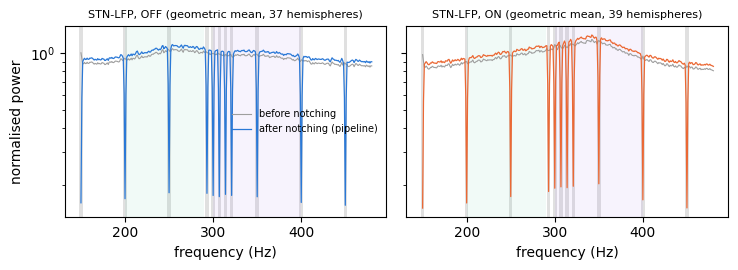

[R2_tables: 0.0 min]
resampling gain re. 50–150 Hz (dB):
                                 step  200 Hz  300 Hz  400 Hz  420 Hz  450 Hz  480 Hz
ds004998: MNE resample 2000 → 1000 Hz   -0.00   -0.00    0.00    0.00   -0.00    0.00
 Oxford: resample_poly 2048 → 1000 Hz   -0.01   -0.01    0.01   -0.02   -0.63   -2.23
[R2_resampling: 0.0 min]


In [5]:
HPI = list(PIPE["hpi_freqs"]); LINE = [PIPE["line_freq"] * k for k in range(1, 10)]
NOTCHES_IN_BAND = [f for f in LINE + HPI if 150 <= f <= 450]


def load_both(path):
    """Pipeline-identical notched segment at 1 kHz + the same segment un-notched (1 kHz and original fs)."""
    import mne
    raw = read_recording(path); fs0 = raw.info["sfreq"]; L = PIPE["seg_len"]
    t0 = rest_segment(raw, L + 2.0)
    if t0 is None:
        return None
    raw.crop(tmin=t0, tmax=t0 + L + 2.0 - 1 / fs0).load_data(verbose="error")
    lf = PIPE["line_freq"]
    types = dict(zip(raw.ch_names, raw.get_channel_types()))
    rr = raw.copy().pick([c for c in raw.ch_names if c.startswith("LFP-") or types[c] == "emg"])
    un2k = rr.copy()
    notch = [lf * k for k in range(1, int(450 // lf) + 1)] + [h for h in PIPE["hpi_freqs"] if h < fs0 / 2]
    nt = rr.copy(); nt.notch_filter(notch, notch_widths=1.0, picks="all", verbose="error"); nt.resample(PIPE["fs"], verbose="error")
    un = rr.copy(); un.resample(PIPE["fs"], verbose="error")
    good = [c for c in rr.ch_names if c not in rr.info["bads"]]

    def bip(r):
        out = {}
        for side in ("left", "right"):
            cont = sorted([c for c in good if c.startswith(f"LFP-{side}-")], key=lambda c: int(c.split("-")[-1]))
            nums = [int(c.split("-")[-1]) for c in cont]
            for (a, na), (b, nb) in zip(zip(cont, nums), zip(cont[1:], nums[1:])):
                if nb == na + 1:
                    out[f"LFP-{side}-{na}{nb}"] = r.get_data(picks=[a])[0] - r.get_data(picks=[b])[0]
        return out
    emg = [c for c, t in zip(nt.ch_names, nt.get_channel_types()) if t == "emg" and c in good]
    return dict(notched=bip(nt), unnotched=bip(un), raw2k=bip(un2k), fs0=fs0,
                emg=nt.get_data(picks=emg) if emg else np.zeros((0, nt.n_times)))


def welch_windows(x, fs, keep=None):
    """1-s Hann windows, 50% overlap; drop windows where keep < 1 anywhere. Returns f, mean PSD, per-window PSDs."""
    n = int(fs); step = n // 2; win = np.hanning(n)
    starts = np.arange(0, len(x) - n + 1, step)
    if keep is not None:
        starts = np.array([s for s in starts if keep[s:s + n].min() >= 1])
    f = np.fft.rfftfreq(n, 1 / fs)
    if len(starts) < 10:                     # < 5 s of usable data (e.g. EMG bursts throughout): no estimate
        return f, np.full(len(f), np.nan), None
    X = np.stack([(x[s:s + n] - x[s:s + n].mean()) * win for s in starts])
    P = np.abs(np.fft.rfft(X, axis=-1)) ** 2 / (fs * (win ** 2).sum()) * 2
    return f, P.mean(0), P


def hfo_variant(f, P, excl_w=2.0, slow=((200, 290),), fast=((300, 400),), band=(200, 420), drop=()):
    if not np.isfinite(P).all():
        return (np.nan,) * 5
    """HFO excess (mean log10 power above a 60–450 Hz 1/f fit), fast/slow ratio and peak, excluding ±excl_w Hz around
    every notch frequency and any (lo, hi) ranges in drop. Same definitions as the pipeline's hfo_stats."""
    m = np.ones_like(f, bool)
    for f0 in notch_freqs(PIPE["fs"]):
        m &= np.abs(f - f0) > excl_w
    for lo, hi in drop:
        m &= ~((f >= lo) & (f <= hi))
    ap, off = aperiodic_fit(f, P[None], 60.0, 450.0)          # the pipeline's robust 1/f fit (±2 Hz notch mask)
    flat = np.log10(np.maximum(P, 1e-300)) - (off[0] - ap[0] * np.log10(np.maximum(f, f[1])))
    mh = m & (f >= band[0]) & (f <= band[1])
    sel = lambda bands: np.any([(f >= lo) & (f <= hi) for lo, hi in bands], 0) & m
    ratio = np.log10(P[sel(fast)].mean() / P[sel(slow)].mean())
    fl = np.where(mh, flat, np.nan); k = np.ones(21) / 21
    sm = np.convolve(np.nan_to_num(fl, nan=np.nanmean(fl)), k, "same")
    return flat[mh].mean(), ratio, f[mh][np.argmax(sm[mh])], sel(slow).sum(), sel(fast).sum()


def line_db(x, fs, f0, half=0.25, nb=(3.0, 8.0)):
    """Narrowband line power at f0 relative to the median of its neighbourhood (dB)."""
    f, P = signal.welch(x, fs, nperseg=int(4 * fs))
    pk = P[np.abs(f - f0) <= half].max(); ref = np.median(P[(np.abs(f - f0) >= nb[0]) & (np.abs(f - f0) <= nb[1])])
    return 10 * np.log10(pk / ref)


VARIANTS = {   # name: kwargs of hfo_variant
    "pipeline (±2 Hz)": dict(),
    "±5 Hz exclusions": dict(excl_w=5.0),
    "±8 Hz exclusions": dict(excl_w=8.0),
    "HPI region removed (285–330 Hz)": dict(drop=((285, 330),), fast=((330, 400),)),
    "notch-free bands": dict(excl_w=5.0, slow=((205, 245), (255, 285)), fast=((330, 345), (355, 395)),
                             drop=((285, 330),)),
}
RAWHFO = {}


def R2_reload():
    fs = int(PIPE["fs"]); n = int(PIPE["seg_len"] * fs)
    groups = list(MAN.groupby(["subject", "med"], sort=True))
    for (subj, med), cand in groups:
        need = M_DS[(M_DS.subject == subj) & (M_DS.med == med)]
        if not len(need):
            continue
        seg = None
        for _, r in cand.iterrows():
            try:
                seg = load_both(r.path)
            except Exception as ex:
                print(f"  ! {Path(r.path).name}: {ex}"); seg = None
            if seg is not None:
                break
        if seg is None:
            continue
        w_emg, _ = emg_mask(seg["emg"][:, :n], fs)
        for rr in need.itertuples():
            pr = rr.pair
            if pr not in seg["notched"]:
                continue
            # as in compute_stats: the HFO statistics use the whole z-scored seg_len segment (no edge trim)
            xn = zs(seg["notched"][pr][:n]); xu = zs(seg["unnotched"][pr][:n])
            x2 = seg["raw2k"][pr]
            keep_emg = w_emg[:n]
            # HFO-band transient mask: 1-s windows with 200–420 Hz power > median + 5 MAD
            hb = np.abs(signal.hilbert(bandpass(xn, 200.0, 420.0, fs))) ** 2
            wp = np.array([hb[s:s + fs].mean() for s in range(0, len(hb) - fs + 1, fs // 2)])
            thr = np.median(wp) + 5 * 1.4826 * np.median(np.abs(wp - np.median(wp)))
            keep_tr = np.ones(len(xn))
            for i_, s in enumerate(range(0, len(hb) - fs + 1, fs // 2)):
                if wp[i_] > thr:
                    keep_tr[s:s + fs] = 0
            f, Pn, _ = welch_windows(xn, fs); _, Pu, _ = welch_windows(xu, fs)
            _, Pe, Wn = welch_windows(xn, fs, keep_emg)
            _, Pt, _ = welch_windows(xn, fs, np.minimum(keep_emg, keep_tr))
            row = dict(subject=subj, side=rr.side, med=med, pair=pr, pipeline_excess=rr.stn_hfo_excess, pipeline_ratio=rr.stn_hfo_ratio,
                       reload_excess=float(hfo_stats(xn[None], fs)[0][0]),
                       kept_emg=keep_emg.mean(), kept_emg_tr=np.minimum(keep_emg, keep_tr).mean(),
                       hpi_db=np.mean([line_db(x2, seg["fs0"], h) for h in HPI]),
                       line_db=np.mean([line_db(x2, seg["fs0"], h) for h in (250.0, 300.0, 350.0, 400.0)]),
                       emg_hfo_r=rr.hfa_emg_r if hasattr(rr, "hfa_emg_r") else np.nan)
            for name, kw in VARIANTS.items():
                ex_, ra_, pk_, ns_, nf_ = hfo_variant(f, Pn, **kw)
                row.update({f"excess|{name}": ex_, f"ratio|{name}": ra_, f"peak|{name}": pk_, f"nslow|{name}": ns_, f"nfast|{name}": nf_})
            for name, PP in (("EMG-masked", Pe), ("EMG+transient-masked", Pt)):
                ex_, ra_, pk_, _, _ = hfo_variant(f, PP)
                row.update({f"excess|{name}": ex_, f"ratio|{name}": ra_, f"peak|{name}": pk_})
            RAWHFO[(subj, rr.side, med)] = dict(row=row, f=f, Pn=Pn, Pu=Pu)
        print(f"  {subj} {med}: done")


def R2_tables():
    D = pd.DataFrame([v["row"] for v in RAWHFO.values()])
    D.to_csv(REV / "R2_hfo_variants_per_recording.csv", index=False)
    r_ex = stats.spearmanr(D.pipeline_excess, D["excess|pipeline (±2 Hz)"])[0]
    r_rl = np.corrcoef(D.pipeline_excess, D.reload_excess)[0, 1]; r_w = np.corrcoef(D.reload_excess, D["excess|pipeline (±2 Hz)"])[0, 1]
    print(f"HFO excess check: reloaded segment vs stored metrics r = {r_rl:.4f} (max |Δ| {np.abs(D.pipeline_excess - D.reload_excess).max():.2e}); "
          f"windowed re-implementation vs pipeline function r = {r_w:.4f}; Spearman vs stored ρ = {r_ex:.3f}")
    # usable bins
    any_row = next(iter(RAWHFO.values()))["row"]
    ub = pd.DataFrame([dict(variant=v, slow_bins=any_row[f"nslow|{v}"], fast_bins=any_row[f"nfast|{v}"]) for v in VARIANTS])
    ub["slow_of"] = 91; ub["fast_of"] = 101
    print("usable 1-Hz bins in the slow (of 200–290 Hz) and fast (of 300–400 Hz) bands:"); print(ub.to_string(index=False))
    rows = []
    for meas in ("excess", "ratio", "peak"):
        for v in list(VARIANTS) + ["EMG-masked", "EMG+transient-masked"]:
            col = f"{meas}|{v}"
            if col not in D:
                continue
            d = paired_frame(D, col); P = d.groupby("subject")[["off", "on"]].mean()
            est, lo, hi, pl, _ = mixed_delta(d)
            rows.append(dict(measure=meas, variant=v, n=len(d), off=d.off.mean(), on=d.on.mean(),
                             p_hemi=stats.wilcoxon(d.off, d.on).pvalue, g=hedges(d.off.values, d.on.values),
                             p_patient=stats.wilcoxon(P.off, P.on).pvalue if len(P) > 5 else np.nan,
                             lmm_delta=est, lmm_lo=lo, lmm_hi=hi, p_lmm=pl))
    T = pd.DataFrame(rows)
    print("\nHFO OFF vs ON under alternative notch exclusions, notch-free bands and masks:"); print(T.round(4).to_string(index=False))
    T.to_csv(REV / "R2_hfo_robustness.csv", index=False); SUMMARY["R2"] = T
    # HPI / line residuals OFF vs ON and as covariate
    for c in ("hpi_db", "line_db", "kept_emg"):
        d = paired_frame(D, c)
        print(f"{c}: OFF {d.off.mean():.2f}, ON {d.on.mean():.2f}, paired p = {stats.wilcoxon(d.off, d.on).pvalue:.3f}")
    dh = paired_frame(D, "excess|pipeline (±2 Hz)").merge(paired_frame(D, "hpi_db"), on=["subject", "side"], suffixes=("", "_hpi"))
    dr = paired_frame(D, "ratio|pipeline (±2 Hz)").merge(paired_frame(D, "hpi_db"), on=["subject", "side"], suffixes=("", "_hpi"))
    for lab, dd in (("HFO excess", dh), ("HFO ratio", dr)):
        rho, p = stats.spearmanr(dd.delta, dd.delta_hpi)
        import statsmodels.formula.api as smf
        m = smf.mixedlm("delta ~ delta_hpi", dd, groups=dd["subject"]).fit(disp=False)
        print(f"Δ{lab} vs ΔHPI-line amplitude: ρ = {rho:+.2f} (p = {p:.3f}); medication effect adjusted for ΔHPI: "
              f"{m.params['Intercept']:+.4f} (p = {m.pvalues['Intercept']:.4f})")
    # figure: grand-average spectra before/after notching
    fs = PIPE["fs"]
    fig, axs = plt.subplots(1, 2, figsize=(7.48, 2.8), sharey=True)
    for ax, med, col in ((axs[0], "MedOff", "#2a78d6"), (axs[1], "MedOn", "#eb6834")):
        ks = [k for k in RAWHFO if k[2] == med]
        f = RAWHFO[ks[0]]["f"]; m = (f >= 150) & (f <= 480)
        nrm = lambda P: P / P[(f >= 60) & (f <= 450)].mean()
        Pu = np.exp(np.mean([np.log(nrm(RAWHFO[k]["Pu"])) for k in ks], 0)); Pn = np.exp(np.mean([np.log(nrm(RAWHFO[k]["Pn"])) for k in ks], 0))
        ax.semilogy(f[m], Pu[m], color="#9e9e9e", lw=.8, label="before notching")
        ax.semilogy(f[m], Pn[m], color=col, lw=.9, label="after notching (pipeline)")
        for f0 in NOTCHES_IN_BAND:
            ax.axvspan(f0 - 2, f0 + 2, color="k", alpha=.12, lw=0)
        ax.axvspan(200, 290, color="#1baf7a", alpha=.06, lw=0); ax.axvspan(300, 400, color="#7b3fe4", alpha=.06, lw=0)
        ax.set_title(f"STN-LFP, {'OFF' if med == 'MedOff' else 'ON'} (geometric mean, {len(ks)} hemispheres)", fontsize=8)
        ax.set_xlabel("frequency (Hz)")
    axs[0].set_ylabel("normalised power"); axs[0].legend(frameon=False, fontsize=7)
    fig.tight_layout(); fig.savefig(REVF / "R2_hfo_notch_spectra.png", dpi=300); plt.show()


def R2_resampling():
    """Power gain (dB) of the two resampling steps for white noise, in the HFO range (0 dB = passband)."""
    import mne
    rng = np.random.default_rng(0)
    x = rng.standard_normal(int(600 * 2000))
    y = mne.io.RawArray(x[None], mne.create_info(["x"], 2000.0, "misc"), verbose="error").resample(1000.0, verbose="error").get_data()[0]
    f0, P0 = signal.welch(x, 2000.0, nperseg=4000); f1, P1 = signal.welch(y, 1000.0, nperseg=2000)
    g_mne = 10 * np.log10(P1 / np.interp(f1, f0, P0))
    x2 = rng.standard_normal(int(600 * 2048)); q = Fraction(1000, 2048)
    y2 = signal.resample_poly(x2, q.numerator, q.denominator)
    f2, P2 = signal.welch(y2, 1000.0, nperseg=2000); f3, P3 = signal.welch(x2, 2048.0, nperseg=4096)
    g_ox = 10 * np.log10(P2 / np.interp(f2, f3, P3))
    rows = [dict(step=lab, **{f"{h} Hz": float(np.interp(h, f, g) - np.median(g[(f > 50) & (f < 150)])) for h in (200, 300, 400, 420, 450, 480)})
            for lab, f, g in (("ds004998: MNE resample 2000 → 1000 Hz", f1, g_mne), ("Oxford: resample_poly 2048 → 1000 Hz", f2, g_ox))]
    T = pd.DataFrame(rows); print("resampling gain re. 50–150 Hz (dB):"); print(T.round(2).to_string(index=False))
    T.to_csv(REV / "R2_resampling_gain.csv", index=False)


run(R2_reload)
run(R2_tables)
run(R2_resampling)

## R3. Model-free test of the β–HFO dissociation; PAC partial associations

In [6]:
def R3():
    import statsmodels.formula.api as smf
    db = paired_frame(M_DS, "stn_beta_res")
    for h in ("stn_hfo_excess", "stn_hfo_ratio"):
        dh = paired_frame(M_DS, h).merge(db, on=["subject", "side"], suffixes=("", "_beta"))
        rho, p = stats.spearmanr(dh.delta_beta, dh.delta)
        P = dh.groupby("subject")[["delta", "delta_beta"]].mean(); rp, pp = stats.spearmanr(P.delta_beta, P.delta)
        m = smf.mixedlm("delta ~ delta_beta", dh, groups=dh["subject"]).fit(disp=False)
        print(f"Δ{h} vs Δβ: hemispheres ρ = {rho:+.2f} (p = {p:.3f}, n = {len(dh)}); patients ρ = {rp:+.2f} (p = {pp:.3f}, n = {len(P)}); "
              f"LMM slope {m.params['delta_beta']:+.3f} (p = {m.pvalues['delta_beta']:.3f}); "
              f"HFO change at Δβ = 0: {m.params['Intercept']:+.4f} (p = {m.pvalues['Intercept']:.4f})")
        SUMMARY[f"R3_{h}"] = dict(rho=rho, p=p, intercept=m.params["Intercept"], p_int=m.pvalues["Intercept"])
    # PAC: unique association with β, HFO and waveform (rank partial correlations), per state
    cov = ["stn_beta_res", "stn_hfo_excess", "stn_sharp_lr", "stn_rdsym"]
    rows = []
    for med in ("MedOff", "MedOn"):
        d = M_DS[M_DS.med == med][["stn_pac_z"] + cov].dropna().rank()
        for c in cov:
            others = [o for o in cov if o != c]
            X = np.column_stack([np.ones(len(d)), d[others].values])
            ry = d.stn_pac_z.values - X @ np.linalg.lstsq(X, d.stn_pac_z.values, rcond=None)[0]
            rx = d[c].values - X @ np.linalg.lstsq(X, d[c].values, rcond=None)[0]
            r, p = stats.pearsonr(rx, ry); rows.append(dict(state=med, covariate=c, partial_rho=r, p=p, n=len(d)))
    T = pd.DataFrame(rows); print("\nSTN PAC (z): rank partial correlations with each covariate, controlling for the others:")
    print(T.round(3).to_string(index=False)); T.to_csv(REV / "R3_pac_partial.csv", index=False)
    L = M_DS[["subject", "side", "med", "stn_pac_z"] + cov].dropna().copy()
    L["on"] = (L.med == "MedOn").astype(float)
    for c in ["stn_pac_z"] + cov:
        L[c] = (L[c] - L[c].mean()) / L[c].std()
    m = smf.mixedlm("stn_pac_z ~ on + stn_beta_res + stn_hfo_excess + stn_sharp_lr + stn_rdsym", L, groups=L["subject"]).fit(disp=False)
    print("\nLMM (standardised): PAC ~ medication + β + HFO + waveform + (1|patient)"); print(m.summary().tables[1])


run(R3)

Δstn_hfo_excess vs Δβ: hemispheres ρ = +0.05 (p = 0.756, n = 37); patients ρ = +0.08 (p = 0.732, n = 19); LMM slope +0.134 (p = 0.101); HFO change at Δβ = 0: +0.0270 (p = 0.0201)
Δstn_hfo_ratio vs Δβ: hemispheres ρ = -0.32 (p = 0.052, n = 37); patients ρ = -0.29 (p = 0.226, n = 19); LMM slope -0.215 (p = 0.215); HFO change at Δβ = 0: +0.0420 (p = 0.1349)

STN PAC (z): rank partial correlations with each covariate, controlling for the others:
 state      covariate  partial_rho     p  n
MedOff   stn_beta_res        0.430 0.008 37
MedOff stn_hfo_excess        0.203 0.228 37
MedOff   stn_sharp_lr       -0.207 0.219 37
MedOff      stn_rdsym        0.107 0.528 37
 MedOn   stn_beta_res        0.268 0.099 39
 MedOn stn_hfo_excess        0.242 0.138 39
 MedOn   stn_sharp_lr        0.066 0.690 39
 MedOn      stn_rdsym        0.047 0.775 39

LMM (standardised): PAC ~ medication + β + HFO + waveform + (1|patient)
                 Coef. Std.Err.       z  P>|z|  [0.025  0.975]
Intercept       -0.066

<local path>
  m = smf.mixedlm("delta ~ delta_beta", dh, groups=dh["subject"]).fit(disp=False)
<local path>
  m = smf.mixedlm("delta ~ delta_beta", dh, groups=dh["subject"]).fit(disp=False)


## R4. Sensitivity of the Δw_GS posterior to the sparsity of the change prior

The joint posteriors were trained under P(change) = 0.5 per candidate. Importance reweighting re-expresses each
hemisphere's posterior under another prior without retraining: weight = p_new(Δ) / p_0(Δ).
(a) only the w_GS component changes (q = 0.25 … 0.95; the hierarchical analysis in R1 is the no-sparsity limit);
(b) all 11 components change together (q = 0.35, 0.65), with the effective sample size reported.

In [7]:
def reweighted_cohort(SS, cols, comps, q, n_draw=4000, seed=0):
    rng = np.random.default_rng(seed); G, ess = [], []
    for key, s in SS.items():
        D = cols(s); lw = np.zeros(len(D))
        for k in comps:
            lw += np.log(p0_density(D[:, k], J_W[k], q) + 1e-300) - np.log(p0_density(D[:, k], J_W[k]) + 1e-300)
        wt = np.exp(lw - lw.max()); wt /= wt.sum(); ess.append(1 / np.sum(wt ** 2))
        G.append(D[rng.choice(len(D), n_draw, p=wt), JP.index("w_GS")])
    G = np.mean(G, 0)
    return np.exp(np.median(G)), np.exp(np.percentile(G, 5)), np.exp(np.percentile(G, 95)), (G < 0).mean(), np.min(ess), np.median(ess)


def R4():
    rows = []
    cols = lambda s: s[:, len(JP):]
    kgs = JP.index("w_GS")
    for q in (0.25, 0.5, 0.75, 0.95):
        r = reweighted_cohort(JS_DS, cols, [kgs], q)
        rows.append(dict(prior="w_GS component only", q=q, wGS_factor=r[0], lo90=r[1], hi90=r[2], P_decrease=r[3], min_ESS=r[4], median_ESS=r[5]))
    for q in (0.35, 0.5, 0.65):
        r = reweighted_cohort(JS_DS, cols, list(range(len(JP))), q)
        rows.append(dict(prior="all 11 components", q=q, wGS_factor=r[0], lo90=r[1], hi90=r[2], P_decrease=r[3], min_ESS=r[4], median_ESS=r[5]))
    T = pd.DataFrame(rows); print("cohort-mean Δw_GS (ON/OFF factor) under alternative change-prior sparsity:")
    print(T.round(3).to_string(index=False)); T.to_csv(REV / "R4_prior_sparsity.csv", index=False); SUMMARY["R4"] = T


run(R4)

cohort-mean Δw_GS (ON/OFF factor) under alternative change-prior sparsity:
              prior    q  wGS_factor  lo90  hi90  P_decrease  min_ESS  median_ESS
w_GS component only 0.25       0.912 0.856 0.970       0.994 3059.602    3280.269
w_GS component only 0.50       0.860 0.797 0.928       0.999 4000.000    4000.000
w_GS component only 0.75       0.820 0.755 0.891       1.000 3161.633    3293.638
w_GS component only 0.95       0.794 0.728 0.871       1.000 1550.733    2366.151
  all 11 components 0.35       0.887 0.829 0.951       0.998 1648.468    1755.134
  all 11 components 0.50       0.860 0.797 0.928       0.999 4000.000    4000.000
  all 11 components 0.65       0.834 0.766 0.908       1.000 1515.958    1749.249
[R4: 0.0 min]


## R5. Misspecified fixed parameters

Simulated OFF/ON pairs whose **fixed** constants differ from the values assumed by the trained networks
(w_SG ±25%, w_GG ×0.5/×2, τ_S and τ_G ×0.8/×1.25, BG delays ×0.8/×1.25). OFF parameters are drawn from the patients'
OFF posteriors (full joint network), so the test lives in the data's regime. Two cases per condition, each with
the same session nuisance as in training:
* **decrease**: w_GS × U(0.7, 0.9), nothing else changes;
* **null**: w_GS unchanged; instead input noise falls (Δlog₁₀σ = −U(0.05, 0.15)) or slow input falls (σ_slow × U(0.5, 0.8)).
The trained joint network (10.6) is applied unchanged. Reported: cohort-mean Δw_GS and P(decrease) per case, the
per-pair AUC (decrease vs null), and the fraction of pairs outside the simulations' reach.

  192 sims: 100.0%  (  222 s)
    statistics: 38 s
Mahalanobis: 0% of recordings beyond the simulations' 99th percentile
  assumed (no misspecification): done
  192 sims: 100.0%  (  224 s)
    statistics: 38 s
Mahalanobis: 0% of recordings beyond the simulations' 99th percentile
  w_SG ×0.75: done
  192 sims: 100.0%  (  222 s)
    statistics: 38 s
Mahalanobis: 0% of recordings beyond the simulations' 99th percentile
  w_SG ×1.25: done
  192 sims: 100.0%  (  222 s)
    statistics: 37 s
Mahalanobis: 0% of recordings beyond the simulations' 99th percentile
  w_GG ×0.5: done
  192 sims: 100.0%  (  222 s)
    statistics: 37 s
Mahalanobis: 0% of recordings beyond the simulations' 99th percentile
  w_GG ×2: done
  192 sims: 100.0%  (  223 s)
    statistics: 37 s
Mahalanobis: 0% of recordings beyond the simulations' 99th percentile
  τ_S, τ_G ×0.8: done
  192 sims: 100.0%  (  223 s)
    statistics: 37 s
Mahalanobis: 0% of recordings beyond the simulations' 99th percentile
  τ_S, τ_G ×1.25: don

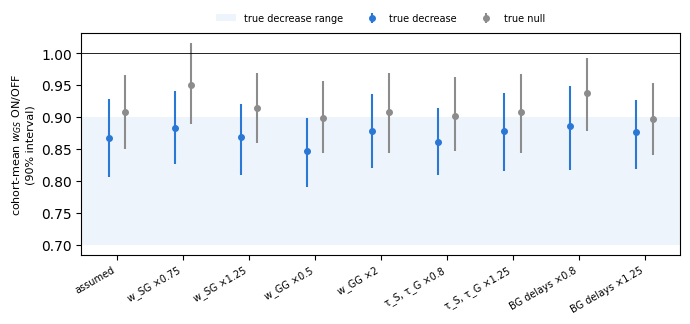

[R5: 43.0 min]


In [8]:
def nuisance_draw(th_off, rng):
    """Session nuisance changes drawn exactly as in training (joint_perturb), candidate changes discarded."""
    th_on, _ = joint_perturb(th_off, rng)
    return nuis_delta(th_off, th_on)


MISSPEC = {"assumed (no misspecification)": {}, "w_SG ×0.75": dict(w_SG=.75), "w_SG ×1.25": dict(w_SG=1.25),
           "w_GG ×0.5": dict(w_GG=.5), "w_GG ×2": dict(w_GG=2.0), "τ_S, τ_G ×0.8": dict(tau_S=.8, tau_G=.8),
           "τ_S, τ_G ×1.25": dict(tau_S=1.25, tau_G=1.25), "BG delays ×0.8": dict(d_SG=.8, d_GS=.8, d_GG=.8),
           "BG delays ×1.25": dict(d_SG=1.25, d_GS=1.25, d_GG=1.25)}


def R5():
    rng = np.random.default_rng(SEED_REV); n = MISSPEC_N
    pool = np.concatenate([s[:, :nP] for s in FS_DS.values()])
    base_c = dict(CIRC); rows = []
    for ci, (cond, mult) in enumerate(MISSPEC.items()):
        th_off = np.clip(pool[rng.integers(0, len(pool), 2 * n)], PRIOR_LO, PRIOR_HI)
        Dm = np.zeros((2 * n, nM))
        Dm[:n, JP.index("w_GS")] = np.log(rng.uniform(.7, .9, n))
        half = n // 2
        Dm[n:n + half, JP.index("log10_sig")] = -rng.uniform(.05, .15, half)
        Dm[n + half:, JP.index("sig_slow")] = np.log(rng.uniform(.5, .8, n - half))
        th_on = apply_full(th_off, Dm, nuisance_draw(th_off, rng))
        try:
            for k, v in mult.items():
                CIRC[k] = base_c[k] * v
            S = simulate_stats(np.concatenate([th_off, th_on]), SEED_REV + 1000 * ci)
        finally:
            CIRC.clear(); CIRC.update(base_c)
        F = pair_features(S[:2 * n], S[2 * n:]); ok = np.isfinite(F).all(1)
        _, oo = ood_report(F[ok], J_F[:J_N], [f"off_{s}" for s in STAT_NAMES] + [f"d_{s}" for s in STAT_NAMES], return_flags=True)
        idx = np.where(ok)[0]
        Dd = [joint_samples(JPOST, F[i], 1000)[:, len(JP) + JP.index("w_GS")] for i in idx]
        pdec = np.array([(d < -J_EPS[JP.index("w_GS")]).mean() for d in Dd]); case = idx < n
        for lab, m in (("decrease", case), ("null", ~case)):
            G = np.mean([d[np.random.default_rng(0).integers(0, len(d), 4000)] for d, mm in zip(Dd, m) if mm], 0)
            rows.append(dict(condition=cond, case=lab, n=m.sum(), wGS_factor=np.exp(np.median(G)), lo90=np.exp(np.percentile(G, 5)),
                             hi90=np.exp(np.percentile(G, 95)), P_cohort_decrease=(G < 0).mean(), mean_Pdec=pdec[m].mean(),
                             frac_outside_reach=np.mean(oo[m]), AUC=_auc(case, pdec)))
        print(f"  {cond}: done")
    T = pd.DataFrame(rows); print("trained joint network under misspecified fixed parameters (true decrease: ×0.7–0.9):")
    print(T.round(3).to_string(index=False)); T.to_csv(REV / "R5_misspecification.csv", index=False); SUMMARY["R5"] = T
    fig, ax = plt.subplots(figsize=(7.0, 3.4))
    ax.axhspan(.7, .9, color="#2a78d6", alpha=.08, lw=0, label="true decrease range")
    conds = list(MISSPEC); x = np.arange(len(conds))
    for j, (lab, col) in enumerate((("decrease", "#2a78d6"), ("null", "#8c8c8c"))):
        s = T[T.case == lab].set_index("condition").loc[conds]
        ax.errorbar(x + (j - .5) * .25, s.wGS_factor, yerr=[s.wGS_factor - s.lo90, s.hi90 - s.wGS_factor], fmt="o", ms=4, color=col, label=f"true {lab}")
    ax.axhline(1, color="k", lw=.6)
    ax.set_xticks(x, [c.replace("assumed (no misspecification)", "assumed") for c in conds], rotation=30, ha="right", fontsize=7)
    ax.set_ylabel("cohort-mean $w_{GS}$ ON/OFF\n(90% interval)", fontsize=8)
    ax.legend(frameon=False, fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.13))
    fig.tight_layout(); fig.savefig(REVF / "R5_misspecification.png", dpi=300); plt.show()


run(R5)

## R5b. Simulation-calibrated null for the cohort result

R5 showed that, with OFF parameters drawn from the patients' posteriors, the trained network reports a cohort-level
w_GS decrease even when w_GS did not change and noise or slow input fell instead. R5b asks the decisive question:
**is the data's cohort shift larger than what the network produces when w_GS does not change?**
For every patient hemisphere, OFF parameters are drawn from its own posterior and ON partners are simulated under
* `nuisance only`: no candidate change (session nuisance only), NULL_REPS draws per hemisphere;
* `noise ↓`: Δlog₁₀σ = −U(0.05, 0.15);  `slow input ↓`: σ_slow × U(0.5, 0.8);  `w_GS ↓`: w_GS × U(0.7, 0.9)
  (3 draws per hemisphere each).
Null cohorts are built by taking one simulated pair per hemisphere (the data's own composition), 2000 times; the
empirical p value is the fraction of null cohorts whose cohort-mean w_GS factor is at or below the data's.
The table of cohort means for all 11 candidates shows whether the data's pattern resembles a w_GS change or a
noise / slow-input change.

In [9]:
def R5b():
    rng = np.random.default_rng(SEED_REV + 55)
    keys = list(FS_DS); kg = JP.index("w_GS"); g0 = len(JP)
    scen = {"nuisance only": NULL_REPS, "noise ↓": 3, "slow input ↓": 3, "w_GS ↓": 3}
    TO, TN, lab, hk = [], [], [], []
    for sc, reps in scen.items():
        for h, k in enumerate(keys):
            s_ = FS_DS[k]; th = np.clip(s_[rng.integers(0, len(s_), reps), :nP], PRIOR_LO, PRIOR_HI)
            Dm = np.zeros((reps, nM))
            if sc == "noise ↓":
                Dm[:, JP.index("log10_sig")] = -rng.uniform(.05, .15, reps)
            elif sc == "slow input ↓":
                Dm[:, JP.index("sig_slow")] = np.log(rng.uniform(.5, .8, reps))
            elif sc == "w_GS ↓":
                Dm[:, kg] = np.log(rng.uniform(.7, .9, reps))
            TO.append(th); TN.append(apply_full(th, Dm, nuisance_draw(th, rng))); lab += [sc] * reps; hk += [h] * reps
    TO, TN, lab, hk = np.concatenate(TO), np.concatenate(TN), np.array(lab), np.array(hk)
    S = simulate_stats(np.concatenate([TO, TN]), SEED_REV + 5500)
    F = pair_features(S[:len(TO)], S[len(TO):]); ok = np.isfinite(F).all(1)
    # posterior mean change of every candidate, and P(decrease) of w_GS, per simulated pair
    MU = np.full((len(F), len(JP)), np.nan); PD = np.full(len(F), np.nan); DR = {}
    for i in np.where(ok)[0]:
        d = joint_samples(JPOST, F[i], 1000)[:, g0:]
        MU[i] = d.mean(0); PD[i] = (d[:, kg] < -J_EPS[kg]).mean(); DR[i] = d[:, kg]
    # data: same summaries from the stored per-hemisphere joint posteriors
    MU_dat = np.array([JS_DS[k][:, g0:].mean(0) for k in JS_DS]); PD_dat = np.array([(JS_DS[k][:, g0 + kg] < -J_EPS[kg]).mean() for k in JS_DS])
    keys_js = list(JS_DS)
    rng_d = np.random.default_rng(0)
    G_dat = np.mean([JS_DS[k][rng_d.integers(0, len(JS_DS[k]), 4000), g0 + kg] for k in keys_js], 0)
    obs = np.exp(np.median(G_dat))

    def cohorts(sc, n_c=2000):
        """Cohort-mean w_GS factor of n_c cohorts with one simulated pair per hemisphere."""
        pools = [np.where((lab == sc) & (hk == h) & ok)[0] for h in range(len(keys))]
        pools = [p for p in pools if len(p)]
        r = np.random.default_rng(1); out = []
        for _ in range(n_c):
            idx = [p[r.integers(len(p))] for p in pools]
            out.append(np.exp(np.median(np.mean([DR[i][r.integers(0, len(DR[i]), 1000)] for i in idx], 0))))
        return np.array(out)

    rows = []
    for sc in scen:
        m = (lab == sc) & ok; C = cohorts(sc)
        rows.append(dict(scenario=sc, pairs=m.sum(), cohort_wGS_median=np.median(C), cohort_wGS_5=np.percentile(C, 5),
                         cohort_wGS_95=np.percentile(C, 95), frac_cohorts_le_data=np.mean(C <= obs), mean_Pdec_wGS=np.nanmean(PD[m]),
                         **{f"mean_d_{p}": np.nanmean(MU[m, j]) for j, p in enumerate(JP)}))
    rows.append(dict(scenario="DATA (ds004998)", pairs=len(keys_js), cohort_wGS_median=obs, mean_Pdec_wGS=PD_dat.mean(),
                     **{f"mean_d_{p}": MU_dat[:, j].mean() for j, p in enumerate(JP)}))
    T = pd.DataFrame(rows)
    print(f"data: cohort-mean w_GS ×{obs:.3f}; mean per-hemisphere P(decrease) {PD_dat.mean():.3f} (prior 0.225)")
    print("frac_cohorts_le_data = empirical p value of the data's cohort shift under each scenario")
    print(T[["scenario", "pairs", "cohort_wGS_median", "cohort_wGS_5", "cohort_wGS_95", "frac_cohorts_le_data", "mean_Pdec_wGS"]].round(3).to_string(index=False))
    print("\nmean posterior change (log factor or additive) of each candidate, per scenario vs data:")
    print(T[["scenario"] + [f"mean_d_{p}" for p in JP]].round(3).to_string(index=False))
    T.to_csv(REV / "R5b_null_calibration.csv", index=False); SUMMARY["R5b"] = T
    # discriminant check: does the data's pattern of mean changes sit closer to the w_GS scenario or to a null?
    for sc in scen:
        m = (lab == sc) & ok
        print(f"  distance of data pattern to '{sc}': "
              f"{np.sqrt(np.sum(((MU_dat.mean(0) - np.nanmean(MU[m], 0)) / J_W) ** 2)):.3f} (in units of the prior width)")


run(R5b)

  1080 sims: 100.0%  (  228 s)
    statistics: 196 s
data: cohort-mean w_GS ×0.861; mean per-hemisphere P(decrease) 0.361 (prior 0.225)
frac_cohorts_le_data = empirical p value of the data's cohort shift under each scenario
       scenario  pairs  cohort_wGS_median  cohort_wGS_5  cohort_wGS_95  frac_cohorts_le_data  mean_Pdec_wGS
  nuisance only    216              0.956         0.933          0.979                 0.000          0.219
        noise ↓    108              0.923         0.900          0.946                 0.000          0.267
   slow input ↓    108              0.886         0.863          0.909                 0.036          0.323
         w_GS ↓    108              0.877         0.859          0.895                 0.080          0.342
DATA (ds004998)     37              0.861           NaN            NaN                   NaN          0.361

mean posterior change (log factor or additive) of each candidate, per scenario vs data:
       scenario  mean_d_w_GS  mean_d_si

## R6. Posterior predictive β change under a less sparse prior; predictive interval widths

In [10]:
def R6():
    kgs = JP.index("w_GS"); rng = np.random.default_rng(SEED_REV + 6); K = 12
    TO, TN, who = [], [], []
    for h, (key, s) in enumerate(FS_DS.items()):
        D = s[:, nP:nP + nM]
        lw = np.log(p0_density(D[:, kgs], J_W[kgs], .95) + 1e-300) - np.log(p0_density(D[:, kgs], J_W[kgs]) + 1e-300)
        wt = np.exp(lw - lw.max()); wt /= wt.sum()
        d = s[rng.choice(len(s), K, p=wt)]
        th_o = np.clip(d[:, :nP], PRIOR_LO, PRIOR_HI)
        TO.append(th_o); TN.append(apply_full(th_o, d[:, nP:nP + nM], d[:, nP + nM:])); who += [h] * K
    TO, TN, who = np.concatenate(TO), np.concatenate(TN), np.array(who)
    S = simulate_stats(np.concatenate([TO, TN]), SEED_REV + 66); SO_, SN_ = S[:len(TO)], S[len(TO):]
    keys = list(FS_DS); jb = STAT_NAMES.index("stn_beta_res")
    obs = np.array([ond.loc[k, "stn_beta_res"] - offd.loc[k, "stn_beta_res"] for k in keys])
    rows = []
    for lab, A, B, W in (("change prior q = 0.5 (§10.7 run)", SO, SN, who_i), ("w_GS prior q = 0.95", SO_, SN_, who)):
        dd = [B[W == h, jb] - A[W == h, jb] for h in range(len(keys))]
        pm = np.array([np.nanmedian(x) for x in dd]); wid = np.array([np.nanpercentile(x, 95) - np.nanpercentile(x, 5) for x in dd])
        cov = np.mean([np.nanpercentile(x, 5) <= o <= np.nanpercentile(x, 95) for x, o in zip(dd, obs)])
        rows.append(dict(posterior=lab, obs_median=np.median(obs), pred_median=np.median(pm), rho=stats.spearmanr(pm, obs)[0],
                         cov90=cov, median_interval_width=np.median(wid)))
    T = pd.DataFrame(rows); print("posterior predictive OFF→ON STN β change:"); print(T.round(3).to_string(index=False))
    T.to_csv(REV / "R6_ppc_sparsity.csv", index=False); SUMMARY["R6"] = T


run(R6)

  864 sims: 100.0%  (  237 s)
    statistics: 161 s
posterior predictive OFF→ON STN β change:
                       posterior  obs_median  pred_median   rho  cov90  median_interval_width
change prior q = 0.5 (§10.7 run)      -0.064       -0.015 0.700  0.861                  0.253
             w_GS prior q = 0.95      -0.064       -0.028 0.662  0.889                  0.254
[R6: 8.0 min]


## R7. Oxford restricted to bipolar channels

In [ ]:
def R7():
    if "OXS" not in globals():
        print("Oxford section not run"); return
    for lab, df in (("Oxford all pairs", OXS), ("Oxford bipolar only", OXS[OXS.bipolar.astype(bool)])):
        pairs = df.groupby(["subject", "side"]).filter(lambda g: g.med.nunique() == 2)
        print(f"\n[{lab}] {pairs.groupby(['subject', 'side']).ngroups} OFF/ON pairs")
        for m in ("stn_beta_res", "stn_ap_exp", "stn_hfo_excess", "stn_hfo_peak_f", "stn_beta_pk_f"):
            d = paired_frame(pairs, m)
            if len(d) >= 3:
                print(f"  {m}: OFF {d.off.mean():.3f} → ON {d.on.mean():.3f}; decreases in {np.mean(d.delta < 0):.0%}; "
                      f"p = {stats.wilcoxon(d.off, d.on).pvalue if len(d) > 4 else np.nan:.3f}")
        if "_joint_cohort" in globals() and pairs.groupby(["subject", "side"]).ngroups >= 3:
            T = _joint_cohort(pairs, lab.replace(" ", "_"))
            if T is not None:
                SUMMARY[f"R7_{lab}"] = T[T.param == "w_GS"]


run(R7)

## R8. Channel selection: β-best instead of HFO-best STN pair

In [12]:
def R8():
    fs = PIPE["fs"]; n = int(PIPE["seg_len"] * fs)
    ncand, rows, same = [], [], 0
    groups = list(MAN.groupby(["subject", "med"], sort=True)); cache = {}
    for (subj, med), cand in groups:
        if not len(M_DS[(M_DS.subject == subj) & (M_DS.med == med)]):
            continue
        for _, r in cand.iterrows():
            try:
                seg = preprocess_recording(r.path)
            except Exception:
                seg = None
            if seg is not None:
                cache[(subj, med)] = seg; break
    for (subj, side), g in M_DS.groupby(["subject", "side"]):
        meds = [m for m in g.med if (subj, m) in cache]
        pairs = set.intersection(*[{p for p, s in cache[(subj, m)]["side"].items() if s == side} for m in meds])
        ncand.append(len(pairs))
        def bpow(x):
            f, P = signal.welch(zs(x[:n]), fs, nperseg=int(2 * fs)); return P[(f >= 13) & (f <= 35)].sum() / P[(f >= 2) & (f <= 45)].sum()
        bp = {p: np.mean([bpow(cache[(subj, m)]["lfp"][p]) for m in meds]) for p in pairs}
        alt = max(bp, key=bp.get); same += int(alt == g.pair.iloc[0])
        for m in meds:
            seg = cache[(subj, m)]; grad = g.grad.iloc[0]
            lfp = seg["lfp"][alt][:n]; meg = seg["grad"][seg["grad_names"].index(grad)][:n]
            w, _ = emg_mask(seg["emg"][:, :n], fs)
            S = compute_stats(lfp[None], meg[None], w=w[None])[0]
            rows.append(dict(subject=subj, side=side, med=m, pair=alt, **dict(zip(STAT_NAMES, S))))
    A = pd.DataFrame(rows); A.to_csv(REV / "R8_beta_best_pair_metrics.csv", index=False)
    print(f"candidate bipolar pairs per hemisphere: {pd.Series(ncand).value_counts().sort_index().to_dict()}; "
          f"β-best = HFO-best pair in {same}/{len(ncand)} hemispheres")
    for m in ("stn_beta_res", "stn_hfo_excess", "stn_hfo_ratio"):
        d = paired_frame(A, m); print(f"  {m}: OFF {d.off.mean():.3f} → ON {d.on.mean():.3f}, p = {stats.wilcoxon(d.off, d.on).pvalue:.4f}")
    o = A[A.med == "MedOff"].set_index(["subject", "side"]); nn = A[A.med == "MedOn"].set_index(["subject", "side"])
    ii = o.index.intersection(nn.index)
    F = pair_features(o.loc[ii, STAT_NAMES].values.astype(float), nn.loc[ii, STAT_NAMES].values.astype(float)); ok = np.isfinite(F).all(1)
    SS = {k: joint_samples(JPOST, x, 4000) for k, x in zip([tuple(k) for k in np.array(list(ii), dtype=object)[ok]], F[ok])}
    rng = np.random.default_rng(0); kg = JP.index("w_GS")
    G = np.mean([s[rng.integers(0, len(s), 4000), len(JP) + kg] for s in SS.values()], 0)
    subj = np.array([k[0] for k in SS]); mv = np.array([flat_likelihood(s[:, len(JP) + kg], J_W[kg]) for s in SS.values()])
    h, _ = hierarchical_normal(mv[:, 0], mv[:, 1], subj, J_W[kg])
    print(f"β-best pair: cohort-mean w_GS ×{np.exp(np.median(G)):.2f} [{np.exp(np.percentile(G, 5)):.2f}, {np.exp(np.percentile(G, 95)):.2f}], "
          f"P(decrease) {(G < 0).mean():.3f}; hierarchical ×{np.exp(h['mu_med']):.2f} [{np.exp(h['mu_lo']):.2f}, {np.exp(h['mu_hi']):.2f}], "
          f"P = {h['P_mu_neg']:.3f} ({len(SS)} hemispheres)")
    SUMMARY["R8"] = dict(same=same, n=len(ncand), factor=np.exp(np.median(G)), P=(G < 0).mean(), hier=np.exp(h["mu_med"]), hierP=h["P_mu_neg"])


run(R8)

candidate bipolar pairs per hemisphere: {1: 3, 2: 2, 3: 30, 7: 4}; β-best = HFO-best pair in 17/39 hemispheres
  stn_beta_res: OFF 0.240 → ON 0.175, p = 0.0018
  stn_hfo_excess: OFF 0.038 → ON 0.058, p = 0.0002
  stn_hfo_ratio: OFF 0.003 → ON 0.072, p = 0.0000
β-best pair: cohort-mean w_GS ×0.86 [0.79, 0.93], P(decrease) 1.000; hierarchical ×0.74 [0.68, 0.81], P = 1.000 (37 hemispheres)
[R8: 6.7 min]


## R9. Clinical associations; simulation partitions

In [13]:
def R9():
    U = load_updrs(DS_ROOT)
    if len(U) < 2:
        print("UPDRS tables not found"); C = pd.DataFrame()
    else:
        rows = []
        for (subj, side), s_ in FS_DS.items():           # OFF w_GS: posterior median of the full joint network
            col = "AR left" if side == "right" else "AR right"
            try:
                a_off, a_on = float(U["MedOff"].loc[subj, col]), float(U["MedOn"].loc[subj, col])
            except (KeyError, ValueError, TypeError):
                continue
            rows.append(dict(subject=subj, side=side, wGS_off=float(np.median(s_[:, IX["w_GS"]])), AR_off=a_off, dAR=a_off - a_on))
        C = pd.DataFrame(rows).dropna()
    if len(C) >= 4:
        C2 = C.merge(paired_frame(M_DS, "stn_beta_res"), on=["subject", "side"])
        for dd, x, y, lab in ((C, "wGS_off", "AR_off", "OFF w_GS vs OFF contralateral akinetic–rigid score"),
                              (C2, "delta", "dAR", "Δβ (ON−OFF) vs clinical improvement (OFF−ON AR)")):
            rho, p = stats.spearmanr(dd[x], dd[y])
            P = dd.groupby("subject")[[x, y]].mean(); rp, pp = stats.spearmanr(P[x], P[y]) if len(P) > 3 else (np.nan, np.nan)
            print(f"{lab}: hemispheres ρ = {rho:+.2f} (p = {p:.3f}, n = {len(dd)}); patients ρ = {rp:+.2f} (p = {pp:.3f}, n = {len(P)}) "
                  f"(exploratory, uncorrected)")
        C2.to_csv(REV / "R9_clinical.csv", index=False)
    print("\nSimulation partitions (no simulation used for validation entered any training set):")
    print(f"  single-session NPE: train = bank[0:{N_SIM}] ({N_SIM}), held-out test = bank[{N_SIM}:{N_SIM + N_RECOVERY}] ({N_RECOVERY})")
    print(f"  hypothesis classifier: {len(F_PAIR)} pairs (OFF from the prior, new seed), 5-fold CV for recovery")
    print(f"  joint networks: train OFF = bank[0:{J_N}] + new ON partners; test OFF = the {N_RECOVERY} held-out bank simulations + new ON partners")


run(R9)

OFF w_GS vs OFF contralateral akinetic–rigid score: hemispheres ρ = -0.00 (p = 0.988, n = 33); patients ρ = +0.02 (p = 0.951, n = 17) (exploratory, uncorrected)
Δβ (ON−OFF) vs clinical improvement (OFF−ON AR): hemispheres ρ = +0.19 (p = 0.287, n = 33); patients ρ = +0.40 (p = 0.116, n = 17) (exploratory, uncorrected)

Simulation partitions (no simulation used for validation entered any training set):
  single-session NPE: train = bank[0:48752] (48752), held-out test = bank[48752:49152] (400)
  hypothesis classifier: 8184 pairs (OFF from the prior, new seed), 5-fold CV for recovery
  joint networks: train OFF = bank[0:24176] + new ON partners; test OFF = the 400 held-out bank simulations + new ON partners
[R9: 0.0 min]


## Summary for the response letter

In [ ]:
for k, v in SUMMARY.items():
    print(f"\n=== {k} ===")
    print(v.round(4).to_string() if isinstance(v, pd.DataFrame) else v)
print(f"\ntables: {REV}\nfigures: {REVF}")